In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 12,
})

textwidth_pt = 472
inch_per_pt = 1 / 72.27
fig_width = textwidth_pt * inch_per_pt
fig_height = fig_width * 0.65

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import copy
import pypesto
import petab
import fides
import pypesto.petab
import amici
import numpy as np
import petab_select
import numpy.matlib as nm
import pandas as pd
import sys
import os
from pathlib import Path

PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "petab").is_dir() and (path / "results").is_dir() and (path / "src").is_dir()
)
os.chdir(PROJECT_ROOT)
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
PETAB_DIR = PROJECT_ROOT / "petab"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
MODEL_SELECTION_RESULTS_DIR = RESULTS_DIR / "model_selection" / "all_ligands_sacess_brute_force_mixed_noise"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
(MODEL_SELECTION_RESULTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
(MODEL_SELECTION_RESULTS_DIR / "figures" / "clustering").mkdir(parents=True, exist_ok=True)

import src.functionalities as func

In [ ]:
import importlib
importlib.reload(func)

In [ ]:
# Map names in sbml model and numbering in the paper to the same names for better readability of the results.
param_to_reaction = {
    'tau_eL': r'$\mathrm{R_{1}}$',
    'k1_Lentry': r'$\mathrm{R_{2}}$',
    'k2_Lentry': r'$\mathrm{R_{3}}$',
    'const_l_degrad': r'$\mathrm{R_{4}}$',
    'v_AhR': r'$\mathrm{R_{5}}$',
    'tau_AhR': r'$\mathrm{R_{6}}$',
    'k1_AhRL': r'$\mathrm{R_{7}}$',
    'k_diss_AhRL': r'$\mathrm{R_{-7}}$',
    'k1_nuclearimport': r'$\mathrm{R_{8}}$',
    'tau_nAhRL': r'$\mathrm{R_{9}}$',
    'v_nARNT': r'$\mathrm{R_{10}}$',
    'tau_nARNT': r'$\mathrm{R_{11}}$',
    'k1_heterodim': r'$\mathrm{R_{12}}$',
    'k_diss_heterodim': r'$\mathrm{R_{-12}}$',
    'k1_dna_ahrr': r'$\mathrm{R_{13}}$',
    'k_diss_dna_ahrr': r'$\mathrm{R_{-13}}$',
    'k1_dna_cyp': r'$\mathrm{R_{14}$',
    'k_diss_dna_cyp': r'$\mathrm{R_{-14}}$',
    'b_AhRR': r'$\mathrm{R_{15}}$',
    'b_AhRR_basal': r'$\mathrm{R_{16}}$',
    'tau_mRNA_AhRR': r'$\mathrm{R_{17}}$',
    'rho_Cyp': r'$\mathrm{R_{18}}$',
    'b_Cyp_basal': r'$\mathrm{R_{19}}$',
    'tau_mRNA_Cyp': r'$\mathrm{R_{20}}$',
    'm_Cyp': r'$\mathrm{R_{21}}$',
    'tau_Cyp1a1': r'$\mathrm{R_{22}}$',
    'k1_Cyp1a1': r'$\mathrm{R_{23}}$',
    'm_AhRR': r'$\mathrm{R_{24}}$',
    'tau_AhRR': r'$\mathrm{R_{25}}$',
    'k1_AhRR_ARNT': r'$\mathrm{R_{26}}$',
    'k_diss_AhRR_ARNT': r'$\mathrm{R_{-26}}$',
    'k1_rep_dna_ahrr': r'$\mathrm{R_{27}}$',
    'k_diss_rep_dna_ahrr': r'$\mathrm{R_{-27}}$',
    'k1_rep_dna_cyp': r'$\mathrm{R_{28}}$',
    'k_diss_rep_dna_cyp': r'$\mathrm{R_{-28}}$',
}

# Data
First we plot the data means with the standard errors for each experimental condition, i.e. each ligand.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import petab
import pandas as pd

data = "ICZ"
noise_model = "mixed_noise"
yaml_file = f"./petab/{data}_{noise_model}/full_petab_problem.yaml"

petab_problem = petab.Problem.from_yaml(yaml_file)

# Extract measurement data
df = petab_problem.measurement_df

# Get unique observables and timepoints
observables = ["mRNA_Cyp1a1_1", "mRNA_AhRR_1"]
observable_labels = [r"Rel. \textit{Cyp1a1} mRNA level", r"Rel. \textit{Ahrr} mRNA level"]
timepoints = np.sort(df['time'].unique())

agg = (
    df.groupby(['observableId', 'time'])['measurement']
      .agg(mean='mean', sd='std', n='count')    # pandas std uses ddof=1 (unbiased)
      .reset_index()
)
agg['sem'] = agg['sd'] / np.sqrt(agg['n'])

# Prepare figure
fig, ax = plt.subplots(1, 2, figsize=(fig_width, 0.65*fig_height))

for obs_ind, obs in enumerate(observables):
    # Subset for this observable
    df_obs = df[df['observableId'] == obs]

    sub = (
    agg[agg['observableId'] == obs]
    .set_index('time')                        # columns: mean, sd, n, sem (from earlier)
    .reindex(timepoints)                       # insert NaNs where missing
)

    x = np.arange(len(timepoints))
    means = sub['mean'].to_numpy()
    yerr  = sub['sem'].to_numpy()   # or 'sd' if showing SD

    # mask out missing timepoints so nothing is drawn
    mask = ~np.isnan(means)
    x_m   = x[mask]
    means_m = means[mask]
    yerr_m  = yerr[mask] if yerr is not None else None
    

    # Plot mean ± std as points with error bars
    ax[obs_ind].errorbar(
        x, means, yerr=yerr,
        fmt='o', capsize=5, markersize=6, elinewidth=1.5,
        label=f"{obs}", color="black"
    )

    # Format axes
    # ax[obs_ind].set_title(obs, fontsize=20)
    ax[obs_ind].set_xlabel("Time [h]", fontsize=14)
    ax[obs_ind].set_ylabel(observable_labels[obs_ind], fontsize=14)
    ax[obs_ind].set_xticks(x)
    ax[obs_ind].set_xticklabels([f'{t/3600:.1f}' for t in timepoints], fontsize=10)
    ax[obs_ind].tick_params(axis='y', labelsize=10)

ax[0].set_ylim(0,99)
ax[1].set_ylim(0,9)

# fig.suptitle("Mean ± SEM per Observable Across Replicates", fontsize=22)
plt.tight_layout(rect=[0, 0, 0.95, 1])
plt.show()

fig.savefig(f"results/figures/{data}_mean_sem_data.png", dpi=300, bbox_inches="tight")

# Separate ligands
Next, we investigate the results of fitting the model to each ligand separately.

### Single ligands visulaizations

In [15]:
import matplotlib.axes
from typing import Union
def visualize_single_observable_model_fit(
        pypesto_result,
        original_pypesto_problem,
        petab_problem,
        start_index: int = 0,
        width = 6,
        height = 4,
        observable_labels = None,
        obs_index = 0,
        objective_customizer = None,
) -> Union[matplotlib.axes.Axes, None]:
    
    pypesto_problem = original_pypesto_problem
    # pypesto_problem.objective= original_pypesto_problem.objective
    if objective_customizer is None:
        pypesto_problem.objective.amici_solver.setMaxSteps(100000)
        pypesto_problem.objective.amici_solver.setRelativeTolerance(1e-12)
        pypesto_problem.objective.amici_solver.setAbsoluteTolerance(1e-8)
        pypesto_problem.objective.amici_solver.setSensitivityMethod(amici.SensitivityMethod_adjoint)

    else:
        objective_customizer(pypesto_problem.objective)

    parameter_mapping = pypesto_problem.objective.parameter_mapping
    edatas = copy.deepcopy(pypesto_problem.objective.edatas)
    amici_model = pypesto_problem.objective.amici_model
    amici_solver = pypesto_problem.objective.amici_solver
    
    
    conditions = sorted(petab_problem.condition_df.index) # since amici gives rdatas with alphabetically sorted conditions
    ncond = len(conditions)

    observable_ids = petab_problem.get_observable_ids()
    if observable_labels == None: 
        observable_labels = observable_ids
    meas_df = petab_problem.measurement_df
    meas_timepoints = meas_df['time'].unique()
    ntimepoints = len(meas_timepoints)
    sim_timepoints = np.linspace(0, meas_timepoints[-1], 100)

    x = pypesto_result.optimize_result.list[start_index]['x'][
        pypesto_problem.x_free_indices
    ]
    objective_result = pypesto_problem.objective(x, return_dict=True)

    x_dct = dict(zip(pypesto_problem.x_names, pypesto_result.optimize_result.list[start_index].x))

    try:
        inner_parameters = objective_result['inner_parameters']
        inner_par_dict = dict(zip(pypesto_problem.inner_x_names, inner_parameters))
        x_dct.update(inner_par_dict)
    except:
        pass

    for j in range(ncond):
        edatas[j].setTimepoints(sim_timepoints)

    amici.parameter_mapping.fill_in_parameters(
        edatas=edatas,
        problem_parameters=x_dct,
        scaled_parameters=True,
        parameter_mapping=parameter_mapping,
        amici_model=amici_model,
    )

    rdatas = amici.runAmiciSimulations(
                amici_model,
                amici_solver,
                edatas,
            )

    # set ticks times
    ticks_times = []
    for t in np.array(range(0,56,8)):
        if 3600*t <= sim_timepoints[-1]:
            ticks_times.append(t)
        
    ticks_times = np.array(ticks_times)

    fig, axs = plt.subplots(1,1,figsize=(width, height), constrained_layout=True)
    axs.plot(rdatas[0].t, rdatas[0].y[:, obs_index], label='Simulation')
    axs.fill_between(rdatas[0].t, rdatas[0].y[:, obs_index]+rdatas[0].sigmay[:,obs_index], rdatas[0].y[:, obs_index]-rdatas[0].sigmay[:,obs_index], label="Std. dev.", alpha=0.1)
    cond = conditions[0]
    meas_means = [np.mean(meas_df[(meas_df['time'] == t) & (meas_df['observableId'] == observable_ids[obs_index])]['measurement'].values)
                    for t in meas_timepoints]
    meas_sem = [np.std(meas_df[(meas_df['time'] == t) & (meas_df['observableId'] == observable_ids[obs_index])]['measurement'].values)/np.sqrt(len(meas_df[(meas_df['time'] == t) & (meas_df['observableId'] == observable_ids[obs_index])]['measurement'].values)-1)
                    for t in meas_timepoints]
    axs.scatter(meas_timepoints, 
                        meas_means, 
                        label='Data', color="black")
    axs.errorbar(meas_timepoints, 
                            meas_means, 
                            yerr=meas_sem, 
                            fmt='o', color="black")
    axs.set_xlabel("Time [h]", fontsize=18)
    axs.set_xticks(ticks_times*3600)
    axs.set_xticklabels([f'{t}' for t in ticks_times], fontsize=14)
    axs.set_ylabel(observable_labels[obs_index], fontsize=18)
    axs.yaxis.set_tick_params(labelsize=14)
    axs.legend(fontsize=18)
    if obs_index == 0:
        axs.set_ylim(0,90)
    elif obs_index == 1:
        axs.set_ylim(0,9)

    print(f'The objective function value is {pypesto_result.optimize_result.get_for_key("fval")[start_index]}\n')
   
    return fig, axs


**3MC model**

In [26]:
model = "bmm_model_reduced"
data = "3MC_mixed_noise"
model_name = f"{model}_{data}"
yaml_file = f"petab/{data}/full_petab_problem.yaml"

MC_petab_problem = petab.Problem.from_yaml(yaml_file)

MC_pypesto_importer = pypesto.petab.PetabImporter(MC_petab_problem, model_name = model_name, hierarchical=False)
model = MC_pypesto_importer.create_model(force_compile=False, verbose=False)
MC_pypesto_objective = MC_pypesto_importer.create_objective()

MC_pypesto_objective.amici_solver.setMaxSteps(100000)
MC_pypesto_objective.amici_solver.setRelativeTolerance(1e-12)
MC_pypesto_objective.amici_solver.setAbsoluteTolerance(1e-8)
MC_pypesto_objective.amici_solver.setSensitivityMethod(amici.SensitivityMethod_adjoint)

MC_pypesto_problem = MC_pypesto_importer.create_problem(MC_pypesto_objective)
objective_creator = MC_pypesto_importer.create_objective_creator()

observable_ids = MC_petab_problem.get_observable_ids()
observable_labels = [r"Rel. \textit{Cyp1a1} mRNA level", r"Rel. \textit{Ahrr} mRNA level"]

In [10]:
optimizer = "sacess"

MC_result = pypesto.store.read_result(f"results/bmm_model/{model_name}_{optimizer}_12h.hdf5")

MC_start_indices = range(0, len(MC_result.optimize_result.list), 10)

Loading the profiling result failed. It is highly likely that no profiling result exists within output/results/bmm_model/bmm_model_reduced_3MC_mixed_noise_sacess_12h.hdf5.
Loading the sampling result failed. It is highly likely that no sampling result exists within output/results/bmm_model/bmm_model_reduced_3MC_mixed_noise_sacess_12h.hdf5.


In [30]:
best_x = MC_result.optimize_result.x[0]
best_x_dct = dict(zip(MC_pypesto_problem.x_names, best_x))

In [ ]:
par_indices = [MC_pypesto_problem.x_names.index(par) for par in np.array(MC_pypesto_problem.x_names)[MC_pypesto_problem.x_free_indices]]
x_labels = [param_to_reaction[par] if par in param_to_reaction.keys() else par for par in np.array(MC_pypesto_problem.x_names)[MC_pypesto_problem.x_free_indices]]

dict(zip(x_labels, MC_result.optimize_result.list[0]["x"][par_indices]))


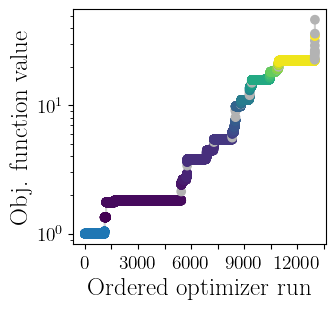

In [60]:
fig, axis = plt.subplots(1,1,figsize=(0.5*fig_width, 0.72*fig_height))
pypesto.visualize.waterfall(MC_result, ax=axis, start_indices=MC_start_indices)
axis.set_title("")
axis.set_ylabel("Obj. function value")
# change fontsizes of all to 14
for item in ([axis.xaxis.label, axis.yaxis.label]):
    item.set_fontsize(18)

for item in (axis.get_xticklabels() + axis.get_yticklabels()):
    item.set_fontsize(14)
from matplotlib.ticker import FuncFormatter

step = 1000  # label every 200th position
axis.xaxis.set_major_formatter(FuncFormatter(
    lambda val, pos: f"{int(val)}" if (int(round(val)) % step) == 0 else ""
))
coll = axis.collections[0]

facecolors = coll.get_facecolors()
r = facecolors[:, 0]
g = facecolors[:, 1]
b = facecolors[:, 2]
red_mask = (r > 0.9) & (g < 0.2) & (b < 0.2)

# Set only the red points to blue (keep alpha as-is)
facecolors[red_mask, 0] = 0.12156863  # R
facecolors[red_mask, 1] = 0.46666667  # G
facecolors[red_mask, 2] = 0.70588235  # B

coll.set_facecolors(facecolors)
# fig.tight_layout()

fig.savefig("results/figures/MC3_waterfall_plot.pdf", bbox_inches='tight')

The objective function value is 77.53003973801802



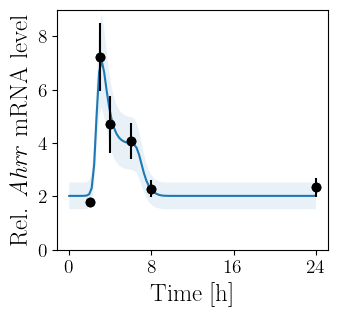

In [52]:
MC_fig, MC_axs = visualize_single_observable_model_fit(MC_result, 
                                                       MC_pypesto_problem, 
                                                       MC_petab_problem, 
                                                       height=0.72*fig_height,
                                                       width=0.5*fig_width,
                                                       start_index=0, 
                                                       obs_index=1,
                                                       observable_labels=observable_labels)

MC_axs.set_title("")
MC_axs.set_ylabel(observable_labels[1], fontsize=18)
MC_axs.get_legend().remove()
# MC_fig.tight_layout()

MC_fig.savefig(f"results/figures/MC3_{observable_ids[1]}_model_fit.pdf", dpi=300, bbox_inches="tight")


**BpA model**

In [34]:
model = "bmm_model_reduced"
data = "BpA_mixed_noise"
model_name = f"{model}_{data}"
yaml_file = f"petab/{data}/full_petab_problem.yaml"

BpA_petab_problem = petab.Problem.from_yaml(yaml_file)

BpA_pypesto_importer = pypesto.petab.PetabImporter(BpA_petab_problem, model_name = model_name, hierarchical=False)
model = BpA_pypesto_importer.create_model(force_compile=False, verbose=False)
BpA_pypesto_objective = BpA_pypesto_importer.create_objective()

BpA_pypesto_objective.amici_solver.setMaxSteps(100000)
BpA_pypesto_objective.amici_solver.setRelativeTolerance(1e-12)
BpA_pypesto_objective.amici_solver.setAbsoluteTolerance(1e-8)
BpA_pypesto_objective.amici_solver.setSensitivityMethod(amici.SensitivityMethod_adjoint)

BpA_pypesto_problem = BpA_pypesto_importer.create_problem(BpA_pypesto_objective)
objective_creator = BpA_pypesto_importer.create_objective_creator()

In [35]:
optimizer = "sacess"

BpA_result = pypesto.store.read_result(f"results/bmm_model/{model_name}_{optimizer}_12h.hdf5")
BpA_start_indices = range(0, len(BpA_result.optimize_result.list), 10)


Loading the profiling result failed. It is highly likely that no profiling result exists within output/results/bmm_model/bmm_model_reduced_BpA_mixed_noise_sacess_12h.hdf5.
Loading the sampling result failed. It is highly likely that no sampling result exists within output/results/bmm_model/bmm_model_reduced_BpA_mixed_noise_sacess_12h.hdf5.


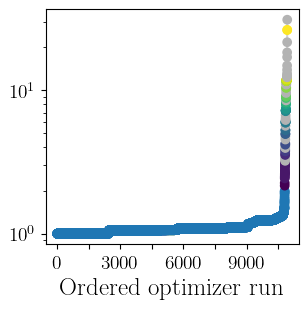

In [59]:
fig, axis = plt.subplots(1,1,figsize=(0.5*fig_width, 0.72*fig_height))
pypesto.visualize.waterfall(BpA_result, ax=axis, start_indices=BpA_start_indices)
axis.set_title("")
axis.set_ylabel("")
# change fontsizes of all to 14
for item in ([axis.xaxis.label, axis.yaxis.label]):
    item.set_fontsize(18)

for item in (axis.get_xticklabels() + axis.get_yticklabels()):
    item.set_fontsize(14)
from matplotlib.ticker import FuncFormatter

step = 1000  # label every 200th position
axis.xaxis.set_major_formatter(FuncFormatter(
    lambda val, pos: f"{int(val)}" if (int(round(val)) % step) == 0 else ""
))

coll = axis.collections[0]

facecolors = coll.get_facecolors()
r = facecolors[:, 0]
g = facecolors[:, 1]
b = facecolors[:, 2]
red_mask = (r > 0.9) & (g < 0.2) & (b < 0.2)

# Set only the red points to blue (keep alpha as-is)
facecolors[red_mask, 0] = 0.12156863  # R
facecolors[red_mask, 1] = 0.46666667  # G
facecolors[red_mask, 2] = 0.70588235  # B

coll.set_facecolors(facecolors)

fig.savefig("results/figures/BpA_waterfall_plot.pdf", dpi=300, bbox_inches="tight")

The objective function value is 29.267767511449502



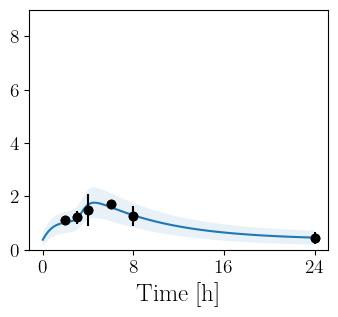

In [49]:
BpA_fig, BpA_axs = visualize_single_observable_model_fit(BpA_result, 
                                                       BpA_pypesto_problem, 
                                                       BpA_petab_problem, 
                                                       height=0.72*fig_height,
                                                       width=0.5*fig_width,
                                                       start_index=0, 
                                                       obs_index=1,
                                                       observable_labels=observable_labels)

BpA_axs.set_title("")
# BpA_axs.set_ylabel(observable_labels[0], fontsize=18)
BpA_axs.set_ylabel("")
BpA_axs.get_legend().remove()

BpA_fig.savefig(f"results/figures/BpA_{observable_ids[1]}_model_fit.pdf", dpi=300, bbox_inches="tight")


**ICZ model**

In [44]:
model = "bmm_model_reduced"
data = "ICZ_mixed_noise"
model_name = f"{model}_{data}"
yaml_file = f"petab/{data}/full_petab_problem.yaml"

ICZ_petab_problem = petab.Problem.from_yaml(yaml_file)

ICZ_pypesto_importer = pypesto.petab.PetabImporter(ICZ_petab_problem, model_name = model_name, hierarchical=False)
model = ICZ_pypesto_importer.create_model(force_compile=False, verbose=False)
ICZ_pypesto_objective = ICZ_pypesto_importer.create_objective()

ICZ_pypesto_objective.amici_solver.setMaxSteps(100000)
ICZ_pypesto_objective.amici_solver.setRelativeTolerance(1e-12)
ICZ_pypesto_objective.amici_solver.setAbsoluteTolerance(1e-8)
ICZ_pypesto_objective.amici_solver.setSensitivityMethod(amici.SensitivityMethod_adjoint)

ICZ_pypesto_problem = ICZ_pypesto_importer.create_problem(ICZ_pypesto_objective)
objective_creator = ICZ_pypesto_importer.create_objective_creator()

In [45]:
optimizer = "sacess"

ICZ_result = pypesto.store.read_result(f"results/bmm_model/{model_name}_{optimizer}_12h.hdf5")
ICZ_start_indices = range(0, len(ICZ_result.optimize_result.list), 10)


Loading the profiling result failed. It is highly likely that no profiling result exists within output/results/bmm_model/bmm_model_reduced_ICZ_mixed_noise_sacess_12h.hdf5.
Loading the sampling result failed. It is highly likely that no sampling result exists within output/results/bmm_model/bmm_model_reduced_ICZ_mixed_noise_sacess_12h.hdf5.


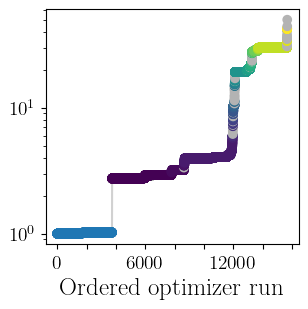

In [53]:
fig, axis = plt.subplots(1,1,figsize=(0.5*fig_width, 0.72*fig_height))
pypesto.visualize.waterfall(ICZ_result, ax=axis, start_indices=ICZ_start_indices)
axis.set_title("")
axis.set_ylabel("")
# change fontsizes of all to 14
for item in ([axis.xaxis.label, axis.yaxis.label]):
    item.set_fontsize(18)

for item in (axis.get_xticklabels() + axis.get_yticklabels()):
    item.set_fontsize(14)
from matplotlib.ticker import FuncFormatter

step = 6000  # label every 200th position
axis.xaxis.set_major_formatter(FuncFormatter(
    lambda val, pos: f"{int(val)}" if (int(round(val)) % step) == 0 else ""
))

coll = axis.collections[0]

facecolors = coll.get_facecolors()
r = facecolors[:, 0]
g = facecolors[:, 1]
b = facecolors[:, 2]
red_mask = (r > 0.9) & (g < 0.2) & (b < 0.2)

# Set only the red points to blue (keep alpha as-is)
facecolors[red_mask, 0] = 0.12156863  # R
facecolors[red_mask, 1] = 0.46666667  # G
facecolors[red_mask, 2] = 0.70588235  # B

coll.set_facecolors(facecolors)


fig.savefig("results/figures/ICZ_waterfall_plot.pdf", bbox_inches="tight")

The objective function value is 96.73001595705199



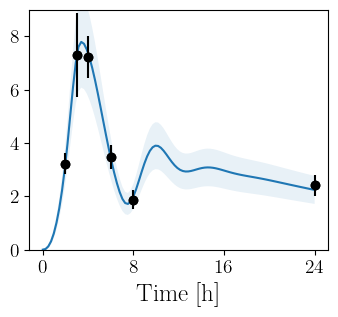

In [58]:
ICZ_fig, ICZ_axs = visualize_single_observable_model_fit(ICZ_result, 
                                                       ICZ_pypesto_problem, 
                                                       ICZ_petab_problem, 
                                                       height=0.72*fig_height,
                                                       width=0.5*fig_width,
                                                       start_index=0, 
                                                       obs_index=1,
                                                       observable_labels=observable_labels)


ICZ_axs.set_title("")
# ICZ_axs.set_ylabel(observable_labels[0], fontsize=18)
ICZ_axs.set_ylabel("")
ICZ_axs.get_legend().remove()

ICZ_fig.savefig(f"results/figures/ICZ_{observable_ids[1]}_model_fit.pdf", bbox_inches="tight")


### Compute ensembles and compare parameters

In [61]:
from pypesto.ensemble import Ensemble

In [62]:
def rotate_axes_90_with_ticks(ax, xlabel=None, ylabel=None):
    """
    Visually rotate a 2D Matplotlib Axes by 90° by swapping x/y for:
      - common artists (lines, scatters, bars, errorbars)
      - axis limits, scales
      - tick locations & tick labels
      - axis labels
    Use immediately after pypesto.visualize.parameter_lowlevel(..., ax=ax).
    """
    # ---- capture current ticks/labels & scales
    x_ticks = ax.get_xticks()
    y_ticks = ax.get_yticks()
    x_ticklabels = [t.get_text() for t in ax.get_xticklabels()]
    y_ticklabels = [t.get_text() for t in ax.get_yticklabels()]
    xscale = ax.get_xscale()
    yscale = ax.get_yscale()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # ---- swap data for common artists
    # lines
    for ln in ax.lines:
        x, y = ln.get_data()
        ln.set_data(y, x)
    # scatters (PathCollection)
    for col in ax.collections:
        offs = col.get_offsets()
        if len(offs):
            col.set_offsets(np.c_[offs[:, 1], offs[:, 0]])
    # errorbars (LineCollection + caplines) – easiest is to redraw their data via artists above
    # bars/rectangles
    for p in ax.patches:
        x, y = p.get_x(), p.get_y()
        w, h = p.get_width(), p.get_height()
        p.set_x(y); p.set_y(x)
        p.set_width(h); p.set_height(w)

    # texts (optional): swap xy if anchored to data coords
    for txt in ax.texts:
        tr = txt.get_transform()
        if tr == ax.transData:  # only swap if placed in data coords
            x, y = txt.get_position()
            txt.set_position((y, x))

    # ---- swap axis properties
    ax.set_xlim(ylim)
    ax.set_ylim(xlim)
    ax.set_xscale(yscale)
    ax.set_yscale(xscale)

    # swap ticks & tick labels
    ax.set_xticks(y_ticks)
    ax.set_yticks(x_ticks)
    # if labels were empty (auto), Matplotlib will generate new ones; else reuse previous
    if any(y_ticklabels):
        ax.set_xticklabels(y_ticklabels)
    if any(x_ticklabels):
        ax.set_yticklabels(x_ticklabels)

    # swap axis labels (or use provided)
    cur_xlab = ax.get_xlabel()
    cur_ylab = ax.get_ylabel()
    ax.set_xlabel(ylabel if ylabel is not None else cur_ylab)
    ax.set_ylabel(xlabel if xlabel is not None else cur_xlab)

    # recompute autoscale & redraw
    ax.relim()
    ax.autoscale_view()


In [63]:
# get parameter ensembles with a specified rel_cutoff
rel_cutoff = 3.84
x_MC = Ensemble.from_optimization_endpoints(MC_result, rel_cutoff = rel_cutoff)
x_BpA = Ensemble.from_optimization_endpoints(BpA_result, rel_cutoff = rel_cutoff)
x_ICZ = Ensemble.from_optimization_endpoints(ICZ_result, rel_cutoff = rel_cutoff)

MC_list = [x_MC.x_vectors[i] for i in range(len(x_MC.x_vectors))]
BpA_list = [x_BpA.x_vectors[i] for i in range(len(x_BpA.x_vectors))]
ICZ_list = [x_ICZ.x_vectors[i] for i in range(len(x_ICZ.x_vectors))]

par_of_interest = [
 'rho_Cyp',
 'b_AhRR',
 'k1_AhRL',
 'k1_Cyp1a1',
 'k_diss_AhRL',
 'k1_heterodim',
 'k_diss_heterodim',
 'k1_Lentry',
 'k2_Lentry',
 'k1_nuclearimport',
 'k1_dna_ahrr',
 'k_diss_dna_ahrr',
 'k1_dna_cyp',
 'k_diss_dna_cyp',
 'tau_nAhRL',
 'tau_eL']

MC_list = list(np.array(MC_list)[[x_MC.x_names.index(par) for par in par_of_interest]])
BpA_list = list(np.array(BpA_list)[[x_BpA.x_names.index(par) for par in par_of_interest]])
ICZ_list = list(np.array(ICZ_list)[[x_ICZ.x_names.index(par) for par in par_of_interest]])

lb = x_MC.lower_bound[[x_MC.x_names.index(par) for par in par_of_interest]]
ub = x_MC.upper_bound[[x_MC.x_names.index(par) for par in par_of_interest]]

The ensemble contains 72783 parameter vectors, which is less than the maximum size.
If you want to include more 
vectors, you can consider raising the cutoff value or including parameters from 
the history with the `from_history` function.
The ensemble contains 108395 parameter vectors, which is less than the maximum size.
If you want to include more 
vectors, you can consider raising the cutoff value or including parameters from 
the history with the `from_history` function.
The ensemble contains 119236 parameter vectors, which is less than the maximum size.
If you want to include more 
vectors, you can consider raising the cutoff value or including parameters from 
the history with the `from_history` function.


In [ ]:
MC_result_small =  pypesto.Result()
MC_result_small.optimize_result.list = MC_result.optimize_result.list[::20]
MC_result_small.problem = MC_pypesto_problem
x_MC_small = Ensemble.from_optimization_endpoints(MC_result_small, rel_cutoff = rel_cutoff, max_size=2000)

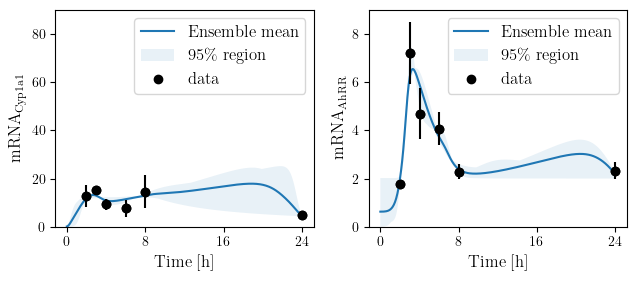

In [83]:
MC_fig, MC_axs = func.custom_visualize_ensembles(x_MC_small, MC_pypesto_problem, MC_petab_problem, plot_measurements=True, quantiles=[0.0,1.0], figsize=(fig_width, 0.7*fig_height))
observable_labels = [r"$\mathrm{mRNA_{Cyp1a1}}$", r"$\mathrm{mRNA_{AhRR}}$"]
for index, ax in enumerate(MC_axs):
    ax.set_title("")
    ax.set_ylabel(observable_labels[index])

MC_axs.flat[0].set_ylim(0,90)
MC_axs.flat[1].set_ylim(0,9)
MC_fig.tight_layout()
MC_fig.savefig(f"results/figures/MC_ensmble_vs_data.png", dpi=300, bbox_inches="tight")

The ensemble contains 1000 parameter vectors, which is less than the maximum size.
If you want to include more 
vectors, you can consider raising the cutoff value or including parameters from 
the history with the `from_history` function.
2026-04-29 12:35:38.623 - amici.swig_wrappers - DEBUG - [BpA][cvodes:cvHandleFailure:ERR_FAILURE] At t = 9829.08 and h = 0.000724668, the error test failed repeatedly or with |h| = hmin.
2026-04-29 12:35:38.624 - amici.swig_wrappers - ERROR - [BpA][FORWARD_FAILURE] AMICI forward simulation failed at t = 9829.08: AMICI failed to integrate the forward problem


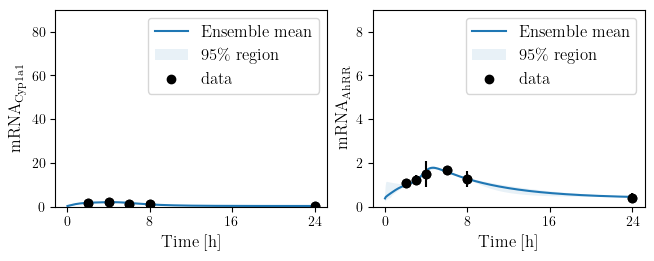

In [66]:
BpA_result_small =  pypesto.Result()
BpA_result_small.optimize_result.list = BpA_result.optimize_result.list[0:100000][::100]
BpA_result_small.problem = BpA_pypesto_problem
x_BpA_small = Ensemble.from_optimization_endpoints(BpA_result_small, rel_cutoff = rel_cutoff, max_size=2000)

BpA_fig, BpA_axs = func.custom_visualize_ensembles(x_BpA_small, BpA_pypesto_problem, BpA_petab_problem, plot_measurements=True, quantiles=[0.0,1.0], figsize=(fig_width, 0.7*fig_height))
observable_labels = [r"$\mathrm{mRNA_{Cyp1a1}}$", r"$\mathrm{mRNA_{AhRR}}$"]
for index, ax in enumerate(BpA_axs):
    ax.set_title("")
    ax.set_ylabel(observable_labels[index])

BpA_axs.flat[0].set_ylim(0,90)
BpA_axs.flat[1].set_ylim(0,9)
BpA_fig.savefig(f"results/figures/BpA_ensmble_vs_data.png", dpi=300, bbox_inches="tight")

The ensemble contains 1193 parameter vectors, which is less than the maximum size.
If you want to include more 
vectors, you can consider raising the cutoff value or including parameters from 
the history with the `from_history` function.
2026-04-29 15:34:46.597 - amici.swig_wrappers - DEBUG - [ICZ][cvodes:cvHandleFailure:ERR_FAILURE] At t = 6915.47 and h = 0.000441115, the error test failed repeatedly or with |h| = hmin.
2026-04-29 15:34:46.598 - amici.swig_wrappers - ERROR - [ICZ][FORWARD_FAILURE] AMICI forward simulation failed at t = 6915.47: AMICI failed to integrate the forward problem


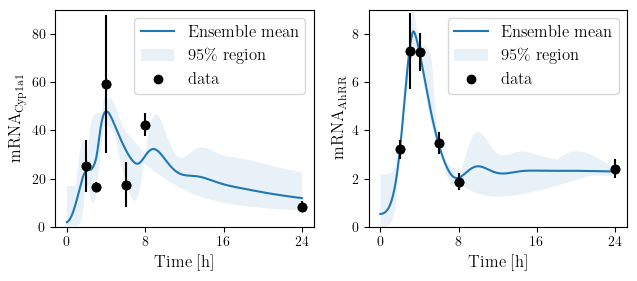

In [85]:
ICZ_result_small =  pypesto.Result()
ICZ_result_small.optimize_result.list = ICZ_result.optimize_result.list[::100]
ICZ_result_small.problem = ICZ_pypesto_problem
x_ICZ_small = Ensemble.from_optimization_endpoints(ICZ_result_small, rel_cutoff = rel_cutoff, max_size=2000)

ICZ_fig, ICZ_axs = func.custom_visualize_ensembles(x_ICZ_small, ICZ_pypesto_problem, ICZ_petab_problem, plot_measurements=True, quantiles=[0.0,1.0], figsize=(fig_width, 0.7*fig_height))

observable_labels = [r"$\mathrm{mRNA_{Cyp1a1}}$", r"$\mathrm{mRNA_{AhRR}}$"]
for index, ax in enumerate(ICZ_axs):
    ax.set_title("")
    ax.set_ylabel(observable_labels[index])

ICZ_axs.flat[0].set_ylim(0,90)
ICZ_axs.flat[1].set_ylim(0,9)
ICZ_fig.tight_layout()
ICZ_fig.savefig(f"results/figures/ICZ_ensmble_vs_data.png", dpi=300, bbox_inches="tight")

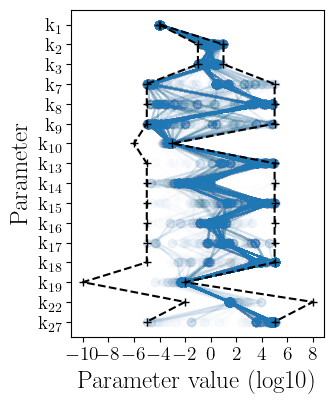

In [71]:
par_indices = [x_BpA.x_names.index(par) for par in par_of_interest]
lb_vector = x_BpA.lower_bound[par_indices]
ub_vector = x_BpA.upper_bound[par_indices]
x_axis_label = "Parameter value (log10)"

abs_cutoff = BpA_result.optimize_result.fval[0] + rel_cutoff
max_size = np.inf

x_vectors = []
fval_vectors = []

for k, start in enumerate(BpA_result.optimize_result.list):
        x_vectors.append(start["x"][BpA_result.problem.x_free_indices][par_indices])
        fval_vectors.append(start["fval"])


# # take only every kth element for the further plotting
# colors = None
# x_vectors = np.array(x_vectors)[::100]
# fval_vectors = fval_vectors[::100]
# colors = pypesto.visualize.clust_color.assign_colors(fval_vectors)


# assign colors based on all vectors and then only take them within a cutoff
# take every 10th vector due to memory issues
colors = None 
x_vectors = np.array(x_vectors)[::100]
fval_vectors = np.asarray(fval_vectors[::100])
colors = pypesto.visualize.clust_color.assign_colors(np.array(fval_vectors), balance_alpha=True)

ens_index = np.where(fval_vectors < abs_cutoff)[0][-1]
# ens_index = 100
x_vectors = x_vectors[0:ens_index]
fval_vectors = fval_vectors[0:ens_index]
colors = colors[0:ens_index]

r = colors[:, 0]
g = colors[:, 1]
b = colors[:, 2]
red_mask = (r > 0.9) & (g < 0.2) & (b < 0.2)

# Set only the red points to blue (keep alpha as-is)
colors[red_mask, 0] = 0.12156863  # R
colors[red_mask, 1] = 0.46666667  # G
colors[red_mask, 2] = 0.70588235  # B

# regulate alphas for other colors
colors[red_mask, 3] = colors[red_mask, 3]
colors[~red_mask, 3] = colors[~red_mask, 3]/2

best_x_vectors = x_vectors[red_mask,:]
best_colors = colors[red_mask,:]
rest_x_vectors = x_vectors[~red_mask,:]
rest_colors = colors[~red_mask,:]
best_fvals = fval_vectors[red_mask]
rest_fvals = fval_vectors[~red_mask]

# from the ones that are not blue take only every 5 again, toa void too big figures
plot_x_vectors = np.append(best_x_vectors, rest_x_vectors[::5,:], axis=0)
plot_colors = np.append(best_colors, rest_colors[::5,:], axis=0)
plot_fval_vectors = np.append(best_fvals, rest_fvals[::5], axis=0)
    

from pypesto.visualize.parameters import parameters_lowlevel

fig, ax = plt.subplots(figsize=(0.5*fig_width, fig_height))
# change parameter name to reaction number
x_labels = [param_to_reaction[par] for par in par_of_interest]

# reorder everything accordingly to the alphabetical order of the labels
import re
def nat_key(lbl: str):
    """
    Natural sort key: 'R2' < 'R10'.
    First tries 'R<digits>' strictly; if not matched, falls back to a generic
    'split by digits' natural key so mixed labels still behave sensibly.
    """
    m = re.fullmatch(r'\s*R(\d+)\s*', lbl)
    if m:
        return (0, int(m.group(1)))       # group 0: clean R<number> labels
    # fallback: natural chunks (text and integers)
    parts = re.findall(r'\d+|\D+', lbl)
    parts = [int(p) if p.isdigit() else p for p in parts]
    return (1, parts)                      # group 1: everything else

# indices in desired left-to-right order
order = sorted(range(len(x_labels)), key=lambda i: nat_key(x_labels[i]), reverse=False)
x_labels = [x_labels[i] for i in order]
x_vectors  = plot_x_vectors[:, order] if plot_x_vectors.size else plot_x_vectors
lb_vector  = lb_vector[order]
ub_vector  = ub_vector[order]


parameters_lowlevel(
            xs=x_vectors,
            fvals=plot_fval_vectors,
            lb=lb_vector,
            ub=ub_vector,
            x_labels=x_labels,
            x_axis_label=x_axis_label,
            ax=ax,
            colors=plot_colors,
            legend_text=None,
            balance_alpha=True,
        )

for item in ([ax.xaxis.label, ax.yaxis.label]):
    item.set_fontsize(18)

for item in (ax.get_xticklabels() + ax.get_yticklabels()):
    item.set_fontsize(14)

ax.set_title("")

# rotate_axes_90_with_ticks(ax, xlabel="Parameter value (log10)", ylabel="Parameter name")
# for lab in ax.get_xticklabels(): lab.set_rotation(0); lab.set_ha('right')
# ax.set_title("Estimated Parameters: BpA", fontsize=14)
# ax.set_title("")
# for item in ([ax.xaxis.label, ax.yaxis.label] +
#              ax.get_xticklabels() + ax.get_yticklabels()):
#     item.set_fontsize(12)
# from matplotlib.ticker import MaxNLocator
# # ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune='both'))
# ax.xaxis.set_major_locator(MaxNLocator(nbins=6, prune='both'))

# plt.tight_layout()


fig.savefig("results/figures/BpA_ensemble_parameter_projectile_plot.pdf", bbox_inches="tight")

# All ligands jointly

In [45]:
model = "bmm_model_reduced"
data = "BpA_3MC_ICZ_mixed_noise"
model_name = f"{model}_{data}"
yaml_file = f"petab/{data}/full_petab_problem.yaml"

petab_problem = petab.Problem.from_yaml(yaml_file)

pypesto_importer = pypesto.petab.PetabImporter(petab_problem, model_name = model_name, hierarchical=False)
model = pypesto_importer.create_model(force_compile=False, verbose=False)
pypesto_objective = pypesto_importer.create_objective()

pypesto_objective.amici_solver.setMaxSteps(100000)
pypesto_objective.amici_solver.setRelativeTolerance(1e-12)
pypesto_objective.amici_solver.setAbsoluteTolerance(1e-8)
pypesto_objective.amici_solver.setSensitivityMethod(amici.SensitivityMethod_adjoint)

pypesto_problem = pypesto_importer.create_problem(pypesto_objective)

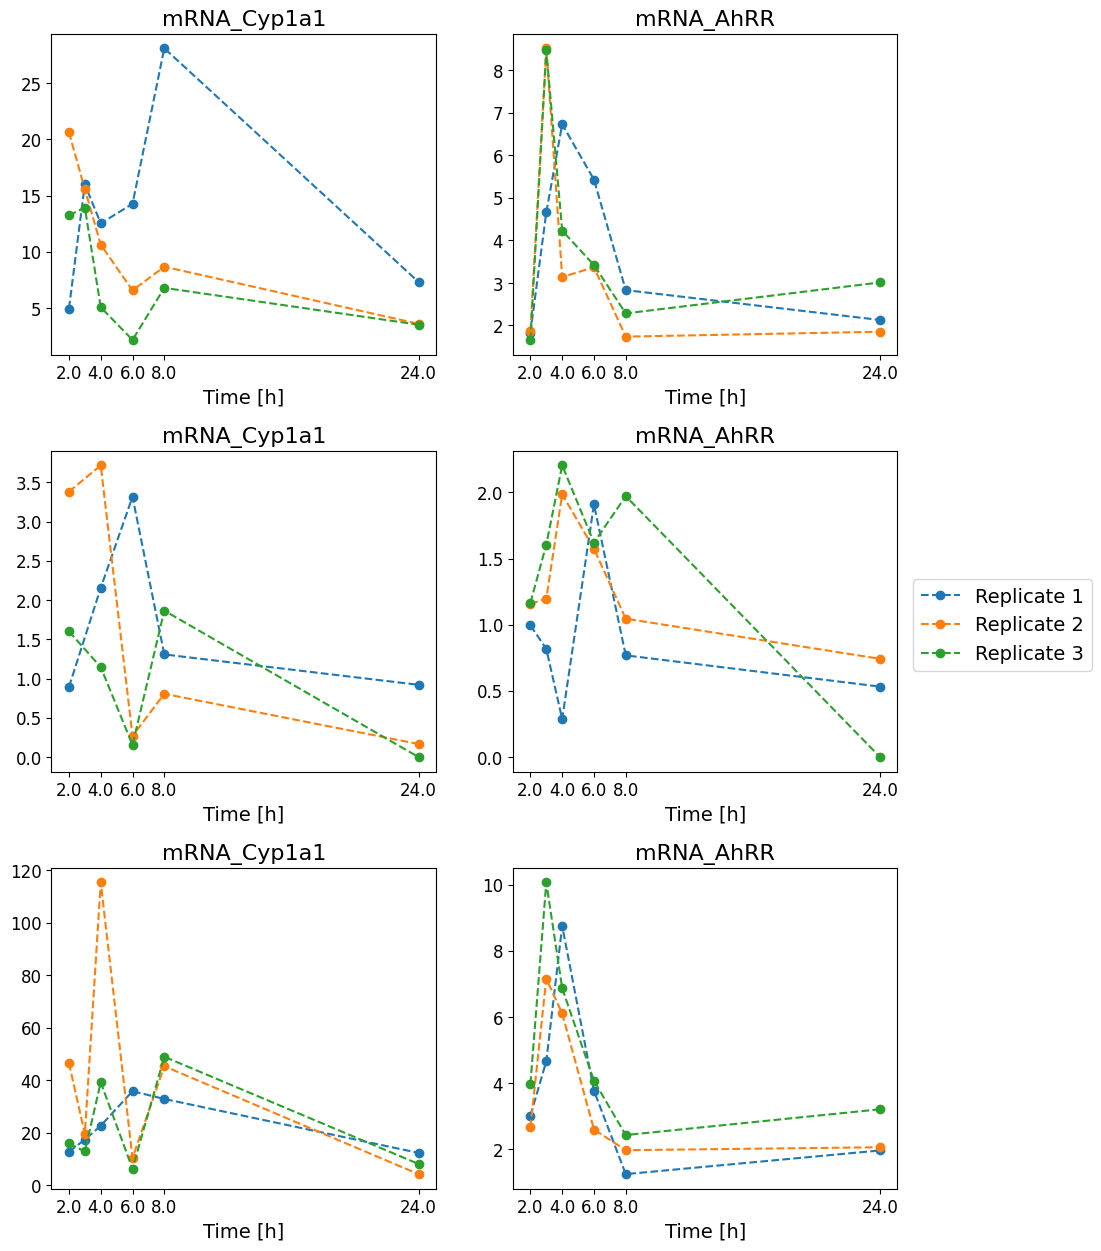

In [26]:
timepoints = petab_problem.measurement_df['time'].unique()
fig, ax = plt.subplots(3,2, figsize=(12,15))
colors = ["blue", "orange", "green"]
for cond_ind, cond in enumerate(petab_problem.condition_df.index):
    for obs_ind, obs in enumerate(petab_problem.observable_df.index):
        for repl_ind, replicate in enumerate(petab_problem.measurement_df[(petab_problem.measurement_df['simulationConditionId'] == cond) & (petab_problem.measurement_df['observableId'] == obs)]['replicateId'].unique()):
            ax[cond_ind, obs_ind].plot(petab_problem.measurement_df['time'][(petab_problem.measurement_df['simulationConditionId'] == cond) & (petab_problem.measurement_df['observableId'] == obs) & (petab_problem.measurement_df['replicateId'] == replicate)],
                                petab_problem.measurement_df['measurement'][(petab_problem.measurement_df['simulationConditionId'] == cond) & (petab_problem.measurement_df['observableId'] == obs) & (petab_problem.measurement_df['replicateId'] == replicate)],
                                linestyle="dashed", marker="o")
            ax[cond_ind, obs_ind].set_title(f"{obs.split('_')[0]}_{obs.split('_')[1]}", fontsize=16)
            ax[cond_ind, obs_ind].set_xlabel("Time [h]", fontsize=14)
            ax[cond_ind, obs_ind].set_xticks(timepoints[[0,2,3,4,5]])
            ax[cond_ind, obs_ind].set_xticklabels([f'{t}' for t in timepoints[[0,2,3,4,5]]/3600], fontsize=12)
            ax[cond_ind, obs_ind].yaxis.set_tick_params(labelsize=12)
            handles, labels = ax[cond_ind, obs_ind].get_legend_handles_labels()
fig.legend(labels = ["Replicate 1", "Replicate 2", "Replicate 3"], loc="center right", fontsize=14)
plt.subplots_adjust(right=0.83, hspace=0.3)

fig.savefig("results/figures/all_ligands_experimental_data.png", dpi=500)

In [39]:
objective_creator = pypesto_importer.create_objective_creator()

In [46]:
optimizer = "sacess"

## This result takes ages, so I manually extracted the good starts.

# result = pypesto.store.read_result(f"results/bmm_model/{model_name}_{optimizer}.hdf5", problem=False, optimize=True, lazy=True)

good_result = pypesto.store.read_result(f"results/bmm_model/{model_name}_{optimizer}_unicorn_best_starts.hdf5")

Loading the sampling result failed. It is highly likely that no sampling result exists within output/results/bmm_model/bmm_model_reduced_BpA_3MC_ICZ_mixed_noise_sacess_unicorn_best_starts.hdf5.


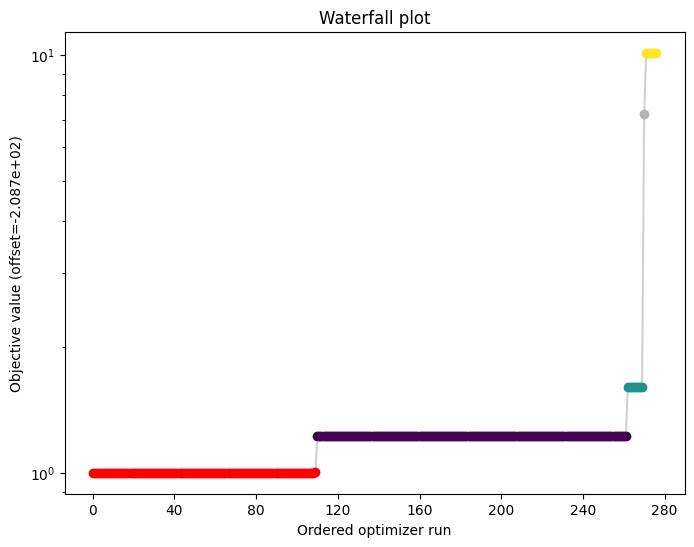

In [66]:
fig, axis = plt.subplots(1,1,figsize=(8,6))
pypesto.visualize.waterfall(good_result, ax=axis)
fig.savefig("results/figures/all_ligands_waterfall_plot.png", dpi=500)

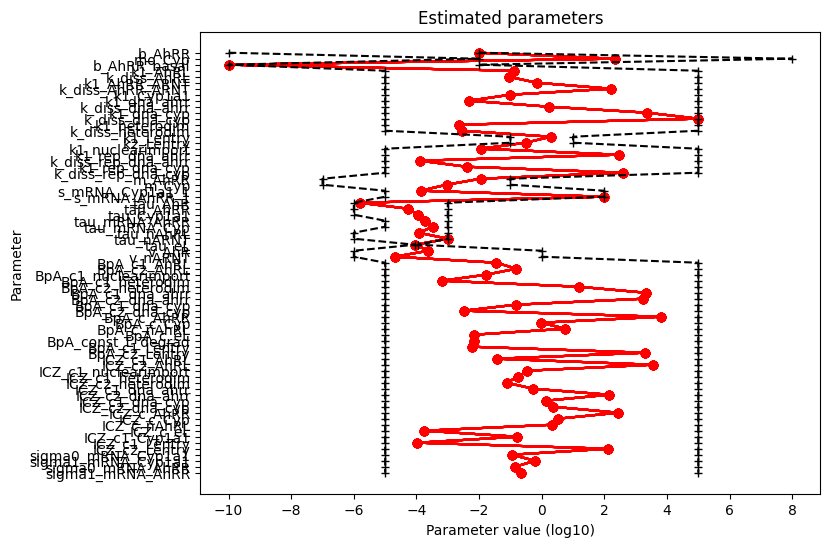

In [64]:
fig, axis = plt.subplots(1,1,figsize=(8,6))
pypesto.visualize.parameters(good_result,
                            size=(8,6),
                            start_indices=20,
                            balance_alpha=False,
                            ax=axis)
fig.savefig("results/figures/all_ligands_parameter_plot.png", dpi=500)

In [ ]:
all_fig, all_axs = func.custom_visualize_model_fit(good_result, pypesto_problem, petab_problem,
                                                   figsize = (1.2*fig_width, 2.2*fig_height),
                                                   start_index=0)
observable_labels = [r"Rel. \textit{Cyp1a1} mRNA level", r"Rel. \textit{Ahrr} mRNA level"]
for axs in all_axs:
    for index, ax in enumerate(axs):
        ax.set_title("")
        ax.set_ylabel(observable_labels[index], fontsize=18)
        ax.get_legend().remove()
        ax. set_xlabel("Time (h)", fontsize=18)
        for item in (ax.get_xticklabels() + ax.get_yticklabels()):
            item.set_fontsize(14)
all_axs.flat[0].set_ylim(0,90)
all_axs.flat[1].set_ylim(0,9)
handles, labels = all_fig.axes[0].get_legend_handles_labels()
all_fig.legend(handles, labels, bbox_to_anchor=(1.05, 0.6), loc='upper left', fontsize=18)


all_fig.savefig("results/figures/all_ligands_model_fit.png", dpi=500)


## Creating a Q-Q plot
To check the noise model assumptions.
Aggregated over conditions and observables (the normalized residuals).

In [ ]:
meas_df = petab_problem.measurement_df.reset_index(drop=True)

In [ ]:
res_dict = pypesto_problem.objective(good_result.optimize_result.x[0][good_result.problem.x_free_indices], sensi_orders=(0,1), return_dict=True)

rdatas = res_dict['rdatas']

sim_df = objective_creator.rdatas_to_simulation_df(rdatas).reset_index(drop=True)
meas_df = petab_problem.measurement_df.reset_index(drop=True)

# get residuals, but be aware dfs are not ordered the same way
full_df = pd.merge(meas_df, sim_df, on=['observableId', 'time', 'simulationConditionId', 'observableParameters', 'datasetId', 'replicateId'], suffixes=('_meas', '_sim'))

sig0_cyp = np.exp(good_result.optimize_result[0].x[good_result.problem.x_names.index('sigma0_mRNA_Cyp1a1')])
sig1_cyp = np.exp(good_result.optimize_result[0].x[good_result.problem.x_names.index('sigma1_mRNA_Cyp1a1')])
sig0_ahrr = np.exp(good_result.optimize_result[0].x[good_result.problem.x_names.index('sigma0_mRNA_AhRR')])
sig1_ahrr = np.exp(good_result.optimize_result[0].x[good_result.problem.x_names.index('sigma1_mRNA_AhRR')])

full_df["residual"] = full_df["measurement"] - full_df["simulation"]
full_df["norm_residual"] = full_df["residual"] / full_df.apply(lambda row: sig0_cyp+sig1_cyp*row.simulation if row.observableId == "mRNA_Cyp1a1"  else sig0_ahrr+sig1_ahrr*row.simulation, axis=1)

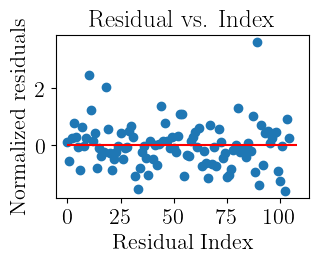

<Figure size 640x480 with 0 Axes>

In [50]:
fig, axs = plt.subplots(1,1, figsize=(fig_width*0.5, fig_height*0.5))
plt.scatter(np.arange(len(full_df["norm_residual"])), full_df["norm_residual"])
plt.hlines(0, xmin=0, xmax=108, color="red")
plt.title("Residual vs. Index", fontsize=18)
plt.xlabel("Residual Index", fontsize=16)
plt.ylabel("Normalized residuals", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()
plt.tight_layout()
fig.savefig("results/figures/residual_vs_index_all_ligands.png", dpi=500, bbox_inches="tight")

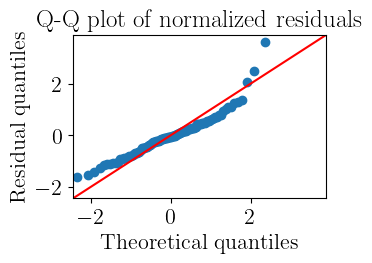

<Figure size 640x480 with 0 Axes>

In [49]:
import statsmodels.api as sm

fig, axs = plt.subplots(1,1, figsize=(fig_width*0.5, fig_height*0.5))
sm.qqplot(full_df["norm_residual"], line="45", ax=axs)
plt.title("Q-Q plot of normalized residuals", fontsize=18)
plt.xlabel("Theoretical quantiles", fontsize=16)
plt.ylabel("Residual quantiles", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()
plt.tight_layout()
fig.savefig("results/figures/qq_plot_all_ligands.png", dpi=500, bbox_inches="tight")

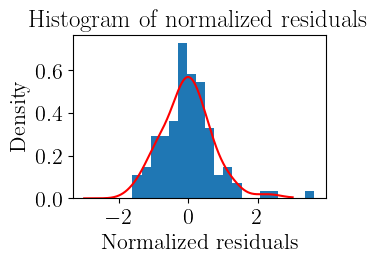

<Figure size 640x480 with 0 Axes>

In [48]:
from scipy import stats
fig, axs = plt.subplots(1,1, figsize=(fig_width*0.5, fig_height*0.5))
kde = stats.gaussian_kde(full_df["norm_residual"])
xx = np.linspace(-3, 3, 1000)
axs.hist(full_df["norm_residual"], bins=20, density=True)
axs.plot(xx, kde(xx), color="red")
plt.title("Histogram of normalized residuals", fontsize=18)
plt.xlabel("Normalized residuals", fontsize=16)
plt.ylabel("Density", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()
plt.tight_layout()
fig.savefig("results/figures/res_hist_all_ligands.png", dpi=500, bbox_inches="tight")